In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import warnings as wr
wr.filterwarnings(action="ignore")
import seaborn as sns

In [4]:
account = pd.read_csv("./Data/Customer Profiles/account_activity.csv")
customer = pd.read_csv("./Data/Customer Profiles/customer_data.csv")
train_fraud = pd.read_csv("./Data/Fraudulent Patterns/train_data.csv")
test_fraud = pd.read_csv("./Data/Fraudulent Patterns/test_data.csv")
suspision = pd.read_csv("./Data/Fraudulent Patterns/suspicious_activity.csv")
merchant = pd.read_csv("./Data/Merchant Information/merchant_data.csv")
tran_cat = pd.read_csv("./Data/Merchant Information/transaction_category_labels.csv")
amount = pd.read_csv("./Data/Transaction Amounts/amount_data.csv")
anamoly = pd.read_csv("./Data/Transaction Amounts/anomaly_scores.csv")
tran_data = pd.read_csv("./Data/Transaction Data/transaction_metadata.csv")
tran_rec = pd.read_csv("./Data/Transaction Data/transaction_records.csv")

In [5]:
data = [account,customer,train_fraud,test_fraud,suspision,merchant,tran_cat,amount,anamoly,tran_data,tran_rec]

for df in data:
    print(df.head())
    print('-'*50)

   CustomerID  AccountBalance   LastLogin
0        1001     9507.272060  2022-01-01
1        1002     7408.704536  2022-01-02
2        1003     1715.321989  2022-01-03
3        1004     3101.509134  2022-01-04
4        1005     5405.766914  2022-01-05
--------------------------------------------------
   CustomerID           Name  Age       Address
0        1001  Customer 1001   54  Address 1001
1        1002  Customer 1002   35  Address 1002
2        1003  Customer 1003   40  Address 1003
3        1004  Customer 1004   30  Address 1004
4        1005  Customer 1005   46  Address 1005
--------------------------------------------------
   TransactionID  FraudIndicator
0            622               0
1            185               0
2            234               0
3            227               1
4            563               0
--------------------------------------------------
   TransactionID  FraudIndicator
0            815               0
1             24               0
2         

In [6]:
costumer_data = pd.merge(customer, account, on='CustomerID')
costumer_data = pd.merge(costumer_data, suspision, on='CustomerID')
costumer_data

,CustomerID,Name,Age,Address,AccountBalance,LastLogin,SuspiciousFlag
0,1001,Customer 1001,54,Address 1001,9507.272060,2022-01-01,0
1,1002,Customer 1002,35,Address 1002,7408.704536,2022-01-02,0
2,1003,Customer 1003,40,Address 1003,1715.321989,2022-01-03,0
3,1004,Customer 1004,30,Address 1004,3101.509134,2022-01-04,0
4,1005,Customer 1005,46,Address 1005,5405.766914,2022-01-05,0
...,...,...,...,...,...,...,...
995,1996,Customer 1996,33,Address 1996,8523.485163,2024-09-22,0
996,1997,Customer 1997,58,Address 1997,9255.451757,2024-09-23,0
997,1998,Customer 1998,25,Address 1998,9148.652759,2024-09-24,0
998,1999,Customer 1999,57,Address 1999,7376.854107,2024-09-25,0


In [7]:
transaction_data1 = pd.merge(train_fraud, tran_cat, on="TransactionID")
transaction_data2 = pd.merge(amount, anamoly, on="TransactionID")
transaction_data3 = pd.merge(tran_data, tran_rec, on="TransactionID")
transaction_data = pd.merge(transaction_data1, transaction_data2,on="TransactionID")
train_transaction_data = pd.merge(transaction_data, transaction_data3,on="TransactionID")
train_transaction_data

,TransactionID,FraudIndicator,Category,TransactionAmount,AnomalyScore,Timestamp,MerchantID,Amount,CustomerID
0,622,0,Food,32.674716,0.658902,2022-01-26 21:00:00,2655,77.368678,1406
1,185,0,Online,29.797542,0.871378,2022-01-08 16:00:00,2166,30.731407,1449
2,234,0,Other,35.945772,0.893479,2022-01-10 17:00:00,2851,69.333272,1221
3,227,1,Travel,29.679255,0.939216,2022-01-10 10:00:00,2776,72.132584,1995
4,563,0,Retail,28.194709,0.762532,2022-01-24 10:00:00,2123,50.946345,1732
...,...,...,...,...,...,...,...,...,...
795,21,0,Travel,60.705354,0.675941,2022-01-01 20:00:00,2835,36.043605,1724
796,736,0,Travel,60.944354,0.515592,2022-01-31 15:00:00,2624,64.233403,1501
797,378,0,Food,43.597486,0.373162,2022-01-16 17:00:00,2477,25.562898,1586
798,894,0,Retail,74.268283,0.229048,2022-02-07 05:00:00,2633,84.718651,1544


In [13]:
transaction_data1 = pd.merge(test_fraud, tran_cat, on="TransactionID")
transaction_data2 = pd.merge(amount, anamoly, on="TransactionID")
transaction_data3 = pd.merge(tran_data, tran_rec, on="TransactionID")
transaction_data = pd.merge(transaction_data1, transaction_data2,on="TransactionID")
test_transaction_data = pd.merge(transaction_data, transaction_data3,on="TransactionID")
test_transaction_data

,TransactionID,FraudIndicator,Category,TransactionAmount,AnomalyScore,Timestamp,MerchantID,Amount,CustomerID
0,815,0,Food,82.094759,0.104405,2022-02-03 22:00:00,2202,94.634165,1056
1,24,0,Retail,13.386778,0.617290,2022-01-01 23:00:00,2480,84.053285,1643
2,332,1,Travel,28.355782,0.221757,2022-01-14 19:00:00,2217,70.867405,1624
3,366,0,Other,80.292030,0.657402,2022-01-16 05:00:00,2597,38.319915,1682
4,314,0,Other,84.894085,0.317943,2022-01-14 01:00:00,2354,39.751781,1968
...,...,...,...,...,...,...,...,...,...
195,602,0,Retail,28.887068,0.326184,2022-01-26 01:00:00,2383,71.221906,1573
196,401,0,Online,11.869897,0.161010,2022-01-17 16:00:00,2933,73.493372,1540
197,993,0,Food,20.875103,0.293701,2022-02-11 08:00:00,2791,31.145357,1695
198,178,0,Online,75.177954,0.479742,2022-01-08 09:00:00,2196,91.896457,1596


In [15]:
train_data = pd.merge(train_transaction_data, costumer_data,on="CustomerID")
train_data

,TransactionID,FraudIndicator,Category,TransactionAmount,AnomalyScore,Timestamp,MerchantID,Amount,CustomerID,Name,Age,Address,AccountBalance,LastLogin,SuspiciousFlag
0,622,0,Food,32.674716,0.658902,2022-01-26 21:00:00,2655,77.368678,1406,Customer 1406,56,Address 1406,6284.739666,2023-02-10,0
1,185,0,Online,29.797542,0.871378,2022-01-08 16:00:00,2166,30.731407,1449,Customer 1449,64,Address 1449,3495.320360,2023-03-25,0
2,234,0,Other,35.945772,0.893479,2022-01-10 17:00:00,2851,69.333272,1221,Customer 1221,37,Address 1221,6722.285664,2022-08-09,0
3,227,1,Travel,29.679255,0.939216,2022-01-10 10:00:00,2776,72.132584,1995,Customer 1995,38,Address 1995,2240.517799,2024-09-21,0
4,563,0,Retail,28.194709,0.762532,2022-01-24 10:00:00,2123,50.946345,1732,Customer 1732,42,Address 1732,6497.372203,2024-01-02,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
795,21,0,Travel,60.705354,0.675941,2022-01-01 20:00:00,2835,36.043605,1724,Customer 1724,32,Address 1724,8830.491513,2023-12-25,0
796,736,0,Travel,60.944354,0.515592,2022-01-31 15:00:00,2624,64.233403,1501,Customer 1501,48,Address 1501,2342.874350,2023-05-16,0
797,378,0,Food,43.597486,0.373162,2022-01-16 17:00:00,2477,25.562898,1586,Customer 1586,40,Address 1586,4726.937231,2023-08-09,0
798,894,0,Retail,74.268283,0.229048,2022-02-07 05:00:00,2633,84.718651,1544,Customer 1544,55,Address 1544,8546.332850,2023-06-28,0


In [17]:
train_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   TransactionID      800 non-null    int64  
 1   FraudIndicator     800 non-null    int64  
 2   Category           800 non-null    object 
 3   TransactionAmount  800 non-null    float64
 4   AnomalyScore       800 non-null    float64
 5   Timestamp          800 non-null    object 
 6   MerchantID         800 non-null    int64  
 7   Amount             800 non-null    float64
 8   CustomerID         800 non-null    int64  
 9   Name               800 non-null    object 
 10  Age                800 non-null    int64  
 11  Address            800 non-null    object 
 12  AccountBalance     800 non-null    float64
 13  LastLogin          800 non-null    object 
 14  SuspiciousFlag     800 non-null    int64  
dtypes: float64(4), int64(6), object(5)
memory usage: 93.9+ KB


In [19]:
test_data = pd.merge(test_transaction_data, costumer_data,on="CustomerID")
test_data

,TransactionID,FraudIndicator,Category,TransactionAmount,AnomalyScore,Timestamp,MerchantID,Amount,CustomerID,Name,Age,Address,AccountBalance,LastLogin,SuspiciousFlag
0,815,0,Food,82.094759,0.104405,2022-02-03 22:00:00,2202,94.634165,1056,Customer 1056,46,Address 1056,3507.492645,2022-02-25,0
1,24,0,Retail,13.386778,0.617290,2022-01-01 23:00:00,2480,84.053285,1643,Customer 1643,52,Address 1643,7833.796203,2023-10-05,0
2,332,1,Travel,28.355782,0.221757,2022-01-14 19:00:00,2217,70.867405,1624,Customer 1624,18,Address 1624,4741.807019,2023-09-16,0
3,366,0,Other,80.292030,0.657402,2022-01-16 05:00:00,2597,38.319915,1682,Customer 1682,39,Address 1682,8191.359573,2023-11-13,0
4,314,0,Other,84.894085,0.317943,2022-01-14 01:00:00,2354,39.751781,1968,Customer 1968,60,Address 1968,8884.809637,2024-08-25,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,602,0,Retail,28.887068,0.326184,2022-01-26 01:00:00,2383,71.221906,1573,Customer 1573,35,Address 1573,8400.252361,2023-07-27,1
196,401,0,Online,11.869897,0.161010,2022-01-17 16:00:00,2933,73.493372,1540,Customer 1540,34,Address 1540,7984.455062,2023-06-24,0
197,993,0,Food,20.875103,0.293701,2022-02-11 08:00:00,2791,31.145357,1695,Customer 1695,35,Address 1695,8553.037244,2023-11-26,0
198,178,0,Online,75.177954,0.479742,2022-01-08 09:00:00,2196,91.896457,1596,Customer 1596,62,Address 1596,7604.035813,2023-08-19,0


In [21]:
test_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   TransactionID      200 non-null    int64  
 1   FraudIndicator     200 non-null    int64  
 2   Category           200 non-null    object 
 3   TransactionAmount  200 non-null    float64
 4   AnomalyScore       200 non-null    float64
 5   Timestamp          200 non-null    object 
 6   MerchantID         200 non-null    int64  
 7   Amount             200 non-null    float64
 8   CustomerID         200 non-null    int64  
 9   Name               200 non-null    object 
 10  Age                200 non-null    int64  
 11  Address            200 non-null    object 
 12  AccountBalance     200 non-null    float64
 13  LastLogin          200 non-null    object 
 14  SuspiciousFlag     200 non-null    int64  
dtypes: float64(4), int64(6), object(5)
memory usage: 23.6+ KB


In [23]:
numerical_features = train_data.select_dtypes(include=['number']).columns.tolist()
categorical_features = train_data.select_dtypes(include=['object']).columns.tolist()
print('Numerical Features:', numerical_features)
print('Categorical Features:', categorical_features)

Numerical Features: ['TransactionID', 'FraudIndicator', 'TransactionAmount', 'AnomalyScore', 'MerchantID', 'Amount', 'CustomerID', 'Age', 'AccountBalance', 'SuspiciousFlag']
Categorical Features: ['Category', 'Timestamp', 'Name', 'Address', 'LastLogin']


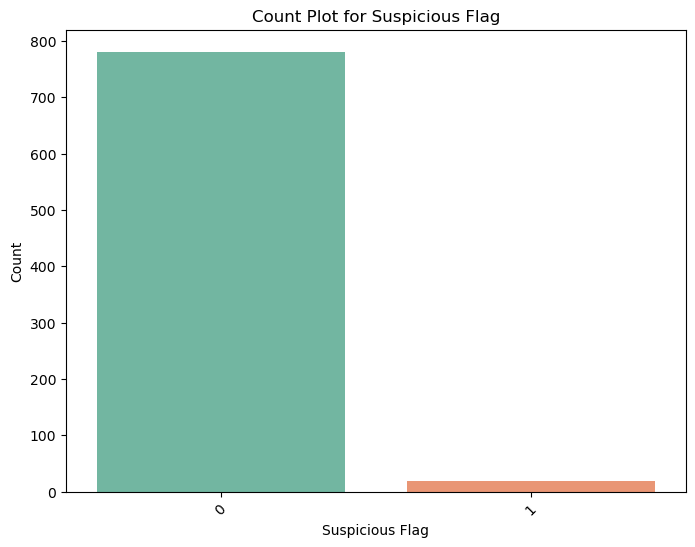

In [25]:
# We should use countplot for SuspiciousFlag feature
plt.figure(figsize=(8, 6))  # Adjust the figure size if needed
sns.countplot(x='SuspiciousFlag', data=train_data, palette='Set2')  # You can change the palette as desired
plt.title('Count Plot for Suspicious Flag')
plt.xlabel('Suspicious Flag')
plt.ylabel('Count')
plt.xticks(rotation=45)  # Rotate x-axis labels if they are long

plt.show()

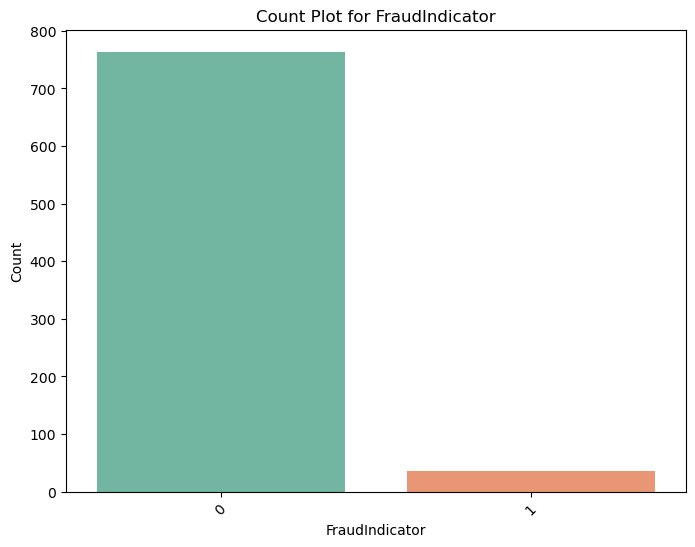

In [27]:
# We should use countplot for SuspiciousFlag feature
plt.figure(figsize=(8, 6))  # Adjust the figure size if needed
sns.countplot(x='FraudIndicator', data=train_data, palette='Set2')  # You can change the palette as desired
plt.title('Count Plot for FraudIndicator')
plt.xlabel('FraudIndicator')
plt.ylabel('Count')
plt.xticks(rotation=45)  # Rotate x-axis labels if they are long

plt.show()

In [29]:
train_data[train_data['SuspiciousFlag'] == 1][['FraudIndicator','SuspiciousFlag']]

,FraudIndicator,SuspiciousFlag
51,0,1
81,0,1
126,0,1
149,0,1
173,0,1
195,0,1
238,0,1
282,0,1
300,1,1
353,1,1


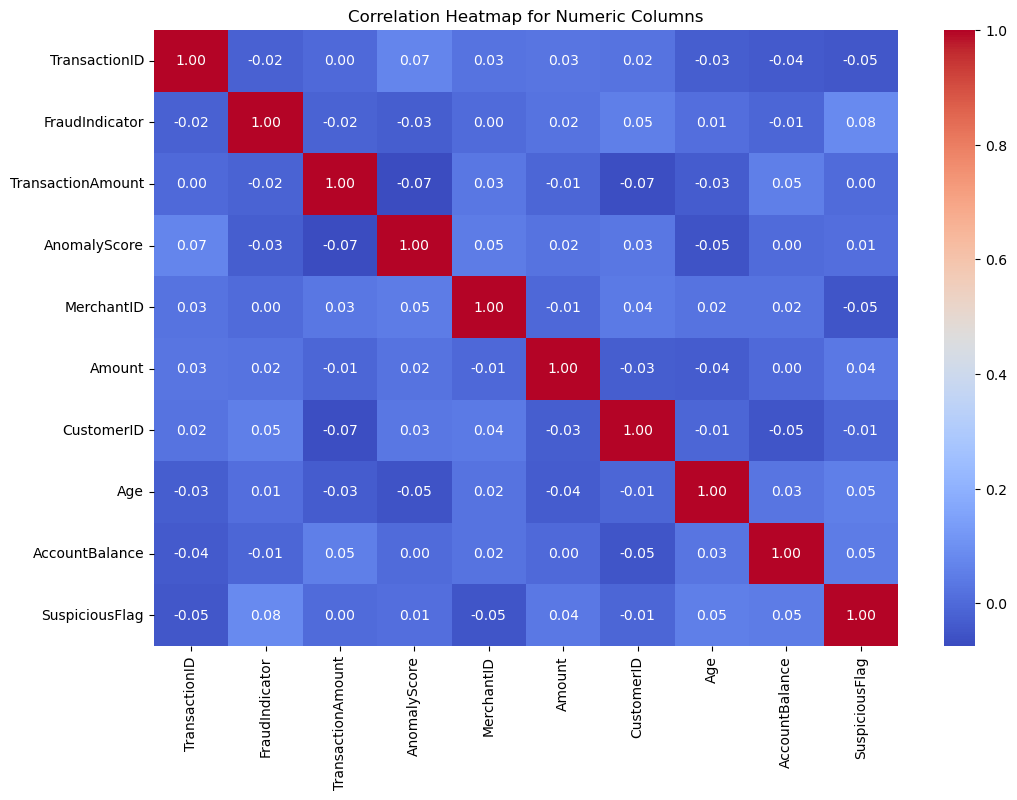

In [31]:
# Select only the numeric columns
numeric_data = train_data.select_dtypes(include=['number'])

# Calculate the correlation matrix for numeric columns
correlation_matrix = numeric_data.corr()

# Create a heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap for Numeric Columns')

plt.show()

In [33]:
# Dropping the columns as of now they are not mush corelated & also wouldn't damper the performance of model
columns_to_be_dropped = ['TransactionID','MerchantID','CustomerID','Name', 'Age', 'Address']

In [35]:
data1 = train_data.drop(columns_to_be_dropped, axis=1)
data1.head()

,FraudIndicator,Category,TransactionAmount,AnomalyScore,Timestamp,Amount,AccountBalance,LastLogin,SuspiciousFlag
0,0,Food,32.674716,0.658902,2022-01-26 21:00:00,77.368678,6284.739666,2023-02-10,0
1,0,Online,29.797542,0.871378,2022-01-08 16:00:00,30.731407,3495.320360,2023-03-25,0
2,0,Other,35.945772,0.893479,2022-01-10 17:00:00,69.333272,6722.285664,2022-08-09,0
3,1,Travel,29.679255,0.939216,2022-01-10 10:00:00,72.132584,2240.517799,2024-09-21,0
4,0,Retail,28.194709,0.762532,2022-01-24 10:00:00,50.946345,6497.372203,2024-01-02,0


In [37]:
data2 = test_data.drop(columns_to_be_dropped, axis=1)
data2.head()

,FraudIndicator,Category,TransactionAmount,AnomalyScore,Timestamp,Amount,AccountBalance,LastLogin,SuspiciousFlag
0,0,Food,82.094759,0.104405,2022-02-03 22:00:00,94.634165,3507.492645,2022-02-25,0
1,0,Retail,13.386778,0.617290,2022-01-01 23:00:00,84.053285,7833.796203,2023-10-05,0
2,1,Travel,28.355782,0.221757,2022-01-14 19:00:00,70.867405,4741.807019,2023-09-16,0
3,0,Other,80.292030,0.657402,2022-01-16 05:00:00,38.319915,8191.359573,2023-11-13,0
4,0,Other,84.894085,0.317943,2022-01-14 01:00:00,39.751781,8884.809637,2024-08-25,0


In [39]:
data1['FraudIndicator'].value_counts(), data1['SuspiciousFlag'].value_counts(), data1['Category'].value_counts()

(FraudIndicator
 0    764
 1     36
 Name: count, dtype: int64,
 SuspiciousFlag
 0    781
 1     19
 Name: count, dtype: int64,
 Category
 Other     169
 Food      167
 Travel    157
 Online    155
 Retail    152
 Name: count, dtype: int64)

In [41]:
data2['FraudIndicator'].value_counts(), data2['SuspiciousFlag'].value_counts(), data2['Category'].value_counts()

(FraudIndicator
 0    191
 1      9
 Name: count, dtype: int64,
 SuspiciousFlag
 0    194
 1      6
 Name: count, dtype: int64,
 Category
 Travel    41
 Other     41
 Online    41
 Retail    40
 Food      37
 Name: count, dtype: int64)

In [43]:
data1['Timestamp1'] = pd.to_datetime(data1['Timestamp'])
data1['Hour'] = data1['Timestamp1'].dt.hour
data1['LastLogin'] = pd.to_datetime(data1['LastLogin'])
data1['gap'] = (data1['Timestamp1'] - data1['LastLogin']).dt.days.abs()
data1.head()

,FraudIndicator,Category,TransactionAmount,AnomalyScore,Timestamp,Amount,AccountBalance,LastLogin,SuspiciousFlag,Timestamp1,Hour,gap
0,0,Food,32.674716,0.658902,2022-01-26 21:00:00,77.368678,6284.739666,2023-02-10,0,2022-01-26 21:00:00,21,380
1,0,Online,29.797542,0.871378,2022-01-08 16:00:00,30.731407,3495.320360,2023-03-25,0,2022-01-08 16:00:00,16,441
2,0,Other,35.945772,0.893479,2022-01-10 17:00:00,69.333272,6722.285664,2022-08-09,0,2022-01-10 17:00:00,17,211
3,1,Travel,29.679255,0.939216,2022-01-10 10:00:00,72.132584,2240.517799,2024-09-21,0,2022-01-10 10:00:00,10,985
4,0,Retail,28.194709,0.762532,2022-01-24 10:00:00,50.946345,6497.372203,2024-01-02,0,2022-01-24 10:00:00,10,708


In [45]:
data2['Timestamp1'] = pd.to_datetime(data2['Timestamp'])
data2['Hour'] = data2['Timestamp1'].dt.hour
data2['LastLogin'] = pd.to_datetime(data2['LastLogin'])
data2['gap'] = (data2['Timestamp1'] - data2['LastLogin']).dt.days.abs()
data2.head()

,FraudIndicator,Category,TransactionAmount,AnomalyScore,Timestamp,Amount,AccountBalance,LastLogin,SuspiciousFlag,Timestamp1,Hour,gap
0,0,Food,82.094759,0.104405,2022-02-03 22:00:00,94.634165,3507.492645,2022-02-25,0,2022-02-03 22:00:00,22,22
1,0,Retail,13.386778,0.617290,2022-01-01 23:00:00,84.053285,7833.796203,2023-10-05,0,2022-01-01 23:00:00,23,642
2,1,Travel,28.355782,0.221757,2022-01-14 19:00:00,70.867405,4741.807019,2023-09-16,0,2022-01-14 19:00:00,19,610
3,0,Other,80.292030,0.657402,2022-01-16 05:00:00,38.319915,8191.359573,2023-11-13,0,2022-01-16 05:00:00,5,666
4,0,Other,84.894085,0.317943,2022-01-14 01:00:00,39.751781,8884.809637,2024-08-25,0,2022-01-14 01:00:00,1,954


In [47]:
from sklearn.preprocessing import LabelEncoder

# Create an instance of LabelEncoder
label_encoder = LabelEncoder()

# Fit and transform the 'Category' column
data1['Category'] = label_encoder.fit_transform(data1['Category'])
data2['Category'] = label_encoder.transform(data2['Category'])

data1, data2

(     FraudIndicator  Category  TransactionAmount  AnomalyScore  \
 0                 0         0          32.674716      0.658902   
 1                 0         1          29.797542      0.871378   
 2                 0         2          35.945772      0.893479   
 3                 1         4          29.679255      0.939216   
 4                 0         3          28.194709      0.762532   
 ..              ...       ...                ...           ...   
 795               0         4          60.705354      0.675941   
 796               0         4          60.944354      0.515592   
 797               0         0          43.597486      0.373162   
 798               0         3          74.268283      0.229048   
 799               0         3          48.775677      0.589367   
 
                Timestamp     Amount  AccountBalance  LastLogin  \
 0    2022-01-26 21:00:00  77.368678     6284.739666 2023-02-10   
 1    2022-01-08 16:00:00  30.731407     3495.320360 2023-03

In [49]:
X_train = data1.drop(['FraudIndicator','Timestamp','Timestamp1','LastLogin'],axis=1)
y_train = data1['FraudIndicator']
X_test = data2.drop(['FraudIndicator','Timestamp','Timestamp1','LastLogin'],axis=1)
y_test = data2['FraudIndicator']

X_train.shape, y_train.shape, X_test.shape, y_test.shape

((800, 8), (800,), (200, 8), (200,))

In [92]:
from sklearn.neural_network import MLPClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, precision_score, recall_score, accuracy_score
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier
import xgboost as xgb

# Scale the features to [0, 1] range
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Apply SMOTE for oversampling
smote = SMOTE(sampling_strategy=1)
X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)

def model_func2(model_name, x_train, y_train, x_test, y_test, param_dict=None):
    if model_name=='DTC':
        model = DecisionTreeClassifier(random_state=0)
        max_depth = np.arange(10, 20, 2)
        criterion = ['entropy', 'gini']
        hyperparameters = dict(max_depth=max_depth, criterion=criterion)
    elif model_name=='XGB':
        model = xgb.XGBClassifier(n_estimators=1000, eta=0.02, random_state=0, learning_rate=0.001)
        max_depth = np.arange(10, 17, 2)
        subsample = np.arange(0.7, 1.01, 0.1)
        hyperparameters = dict(max_depth=max_depth, subsample=subsample)
    elif model_name=='BAG':
        model = BaggingClassifier(n_estimators=1000, random_state=0, n_jobs=-1)
        max_samples = [0.5, 0.8, 1.0]
        hyperparameters = dict(max_samples=max_samples)
    elif model_name=='RF':
        model = RandomForestClassifier(n_estimators=1000, oob_score=True, n_jobs=-1, random_state=0)
        max_depth = np.arange(13, 17, 1)
        hyperparameters = dict(max_depth=max_depth)
    elif model_name=='LogR':
        model = LogisticRegression(random_state=0, max_iter=1000, n_jobs=-1)
        C = [0.01, 0.1, 1.0, 10.0]
        penalty = ['l1', 'l2']
        hyperparameters = dict(C=C, penalty=penalty)
    elif model_name=='NN':
        model = MLPClassifier(hidden_layer_sizes=(11,), alpha=0.001, max_iter=1000, random_state=0)
        activation = ['logistic', 'tanh', 'relu']  # 激活函数
        hyperparameters = dict(activation=activation)
        
    if(param_dict is not None):
        hyperparameters = param_dict
    
    gridsearch = GridSearchCV(model, hyperparameters, cv=10, verbose=1, n_jobs=-1, scoring='f1')
    best_model = gridsearch.fit(x_train, y_train)
    print('best_', model_name, ': ', best_model.best_params_)

    ini_train_pred = best_model.predict(x_train) #Threshold = 0.5
    ini_train_f1 = f1_score(y_pred=ini_train_pred, y_true=y_train, average='binary', pos_label=1)
    ini_train_recall = recall_score(y_pred=ini_train_pred, y_true=y_train, average='binary', pos_label=1)
    ini_train_precision = precision_score(y_pred=ini_train_pred, y_true=y_train, average='binary', pos_label=1)
    ini_train_accuracy = accuracy_score(y_pred=ini_train_pred, y_true=y_train)
    print('initial-train %s: f1=%.3f, recall=%.3f, precision=%.3f, accuracy=%.3f' % (
          model_name, ini_train_f1, ini_train_recall, ini_train_precision, ini_train_accuracy))

    ini_test_pred = best_model.predict(x_test) #Threshold = 0.5
    ini_test_f1 = f1_score(y_pred=ini_test_pred, y_true=y_test, average='binary', pos_label=1)
    ini_test_recall = recall_score(y_pred=ini_test_pred, y_true=y_test, average='binary', pos_label=1)
    ini_test_precision = precision_score(y_pred=ini_test_pred, y_true=y_test, average='binary', pos_label=1)
    ini_test_accuracy = accuracy_score(y_pred=ini_test_pred, y_true=y_test)
    print('initial-test %s: f1=%.3f, recall=%.3f, precision=%.3f, accuracy=%.3f' % (
          model_name, ini_test_f1, ini_test_recall, ini_test_precision, ini_test_accuracy))

    '''
    Assuming your target is (0,1), then the classifier would output a probability matrix of dimension (N,2). 
    The first index refers to the probability that the data belong to class 0, 
    and the second refers to the probability that the data belong to class 1.
    '''

    yes_index = list(best_model.classes_).index(1)  # yes 位置
    # model_yes_proba = model_proba[yes_index::2]  # 取yes
    
    model_yes_proba = best_model.predict_proba(x_train)[:, yes_index]  # 取yes
    # print(model_yes_proba)
    
    model_train = pd.DataFrame()
    model_train['correct'] = y_train  # y_train存在index 合并会出错
    model_train['yes_prob'] = model_yes_proba
    model_train.sort_values(by='yes_prob', ascending=False, inplace=True)  # ascending=False 倒叙
    model_train.reset_index(drop=True, inplace=True)
    # print(model_train)

    pred = [0] * model_train.shape[0]
    f1_prob_dict = dict()
    
    for x in range(0, model_train.shape[0] - 1):
        pred[x] = 1
        f1 = f1_score(y_pred=pred, y_true=model_train['correct'], average='binary', pos_label=1)
        this_prob = model_train['yes_prob'][x:x + 2].mean()
        f1_prob_dict[this_prob] = f1
        
    f1_max = max(f1_prob_dict.values())
    prob_max = max(f1_prob_dict, key=f1_prob_dict.get)  # 获得字典dict中value的最大值所对应的键的方法
    
    pred = [1 if y >= prob_max else 0 for y in model_train['yes_prob']]

    recall = recall_score(y_pred=pred, y_true=model_train['correct'], average='binary', pos_label=1)
    precision = precision_score(y_pred=pred, y_true=model_train['correct'], average='binary', pos_label=1)
    accuracy = accuracy_score(y_pred=pred, y_true=model_train['correct'])

    print('probability=%.3f' % prob_max)
    print('After-train %s: f1=%.3f, recall=%.3f, precision=%.3f, accuracy=%.3f' % (
          model_name, f1_max, recall, precision, accuracy))

    model_test_proba = best_model.predict_proba(x_test)[:, yes_index]  # 猜一类的机率
    prob_max_pred = [1 if y >= prob_max else 0 for y in model_test_proba]
    
    f1 = f1_score(y_pred=prob_max_pred, y_true=y_test, average='binary', pos_label=1)
    recall = recall_score(y_pred=prob_max_pred, y_true=y_test, average='binary', pos_label=1)
    precision = precision_score(y_pred=prob_max_pred, y_true=y_test, average='binary', pos_label=1)
    accuracy = accuracy_score(y_pred=prob_max_pred, y_true=y_test)
    print('After-test %s: f1=%.3f, recall=%.3f, precision=%.3f, accuracy=%.3f' % (
        model_name, f1, recall, precision, accuracy))
    print('-'*100)

In [94]:
model_func2(model_name='DTC',  x_train=X_train_smote, y_train=y_train_smote, x_test=X_test, y_test=y_test)
#model_func2(model_name='XGB',  x_train=X_train_smote, y_train=y_train_smote, x_test=X_test, y_test=y_test)
#model_func2(model_name='BAG',  x_train=X_train_smote, y_train=y_train_smote, x_test=X_test, y_test=y_test)
#model_func2(model_name='RF',   x_train=X_train_smote, y_train=y_train_smote, x_test=X_test, y_test=y_test)
model_func2(model_name='LogR', x_train=X_train_smote, y_train=y_train_smote, x_test=X_test, y_test=y_test)
#model_func2(model_name='NN',   x_train=X_train_smote, y_train=y_train_smote, x_test=X_test, y_test=y_test)

Fitting 10 folds for each of 10 candidates, totalling 100 fits
best_ DTC :  {'criterion': 'entropy', 'max_depth': 18}
initial-train DTC: f1=1.000, recall=1.000, precision=1.000, accuracy=1.000
initial-test DTC: f1=0.000, recall=0.000, precision=0.000, accuracy=0.955
probability=0.500
After-train DTC: f1=1.000, recall=1.000, precision=1.000, accuracy=1.000
After-test DTC: f1=0.000, recall=0.000, precision=0.000, accuracy=0.955
----------------------------------------------------------------------------------------------------
Fitting 10 folds for each of 8 candidates, totalling 80 fits
best_ LogR :  {'C': 0.01, 'penalty': 'l2'}
initial-train LogR: f1=0.574, recall=0.573, precision=0.576, accuracy=0.575
initial-test LogR: f1=0.098, recall=0.889, precision=0.052, accuracy=0.265
probability=0.478
After-train LogR: f1=0.707, recall=0.966, precision=0.558, accuracy=0.600
After-test LogR: f1=0.098, recall=0.889, precision=0.052, accuracy=0.265
-------------------------------------------------

In [130]:
# Logistic Regression model
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.preprocessing import MinMaxScaler
from imblearn.over_sampling import SMOTE

# Scale the features to [0, 1] range
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Apply SMOTE for oversampling
smote = SMOTE(sampling_strategy=0.4)
X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)

# Create a logistic regression model
model = LogisticRegression() #DecisionTreeClassifier(random_state=42) #RandomForestClassifier(n_estimators=100, class_weight="balanced") #LogisticRegression()

# Train the model on the training data
model.fit(X_train_smote, y_train_smote)

# Make predictions on the testing data
y_pred = model.predict(X_test)

# Calculate the accuracy of the model
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
confusion = confusion_matrix(y_test, y_pred)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)
print("Confusion Matrix:")
print(confusion)

Accuracy: 0.045
Precision: 0.045
Recall: 1.0
F1 Score: 0.0861244019138756
Confusion Matrix:
[[  0 191]
 [  0   9]]


In [65]:
# Logistic Regression model
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# Create a logistic regression model
model = RandomForestClassifier(n_estimators=300, class_weight="balanced")

# Train the model on the training data
model.fit(X_train, y_train)

# Make predictions on the testing data
y_pred = model.predict(X_test)

# Calculate the accuracy of the model
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
confusion = confusion_matrix(y_test, y_pred)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)
print("Confusion Matrix:")
print(confusion)

Accuracy: 0.955
Precision: 0.0
Recall: 0.0
F1 Score: 0.0
Confusion Matrix:
[[191   0]
 [  9   0]]


In [169]:
import numpy as np
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import MinMaxScaler
from imblearn.over_sampling import SMOTE
from sklearn.tree import DecisionTreeClassifier

# Scale the features to [0, 1] range
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Apply SMOTE for oversampling
smote = SMOTE()
X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)

# Define FROST function
def generate_frost_samples(X_minority, initial_feature_index, k=5, m=1.5):
    initial_feature_values = X_minority[:, initial_feature_index]
    similarity_matrix = 1 / (1 + np.abs(initial_feature_values[:, np.newaxis] - initial_feature_values))
    k_nearest_indices = np.argsort(similarity_matrix, axis=1)[:, -k:]
    synthetic_samples_initial = []
    for i in range(len(initial_feature_values)):
        for j in k_nearest_indices[i]:
            synthetic_value = initial_feature_values[i] + m * (initial_feature_values[j] - initial_feature_values[i])
            synthetic_sample = np.copy(X_minority[i])
            synthetic_sample[initial_feature_index] = synthetic_value
            synthetic_samples_initial.append(synthetic_sample)
    return np.array(synthetic_samples_initial)

# Apply FROST for oversampling
initial_feature_index = 0  # Choose the index of the initial feature to oversample
X_train_frost = generate_frost_samples(X_train_scaled[y_train == 1], initial_feature_index, k=5, m=1.5)

# Combine original and synthetic samples
X_train_combined = np.vstack((X_train_scaled, X_train_frost))
y_train_combined = np.concatenate((y_train, np.ones(len(X_train_frost))))

# Initialize the Decision Tree Classifier
clf = DecisionTreeClassifier(random_state=42)

# Define the number of folds for k-fold cross-validation
k_folds = KFold(n_splits=5)

# Perform cross-validation and calculate the scores for SMOTE
scores_smote = cross_val_score(clf, X_train_smote, y_train_smote, cv=k_folds)

# Perform cross-validation and calculate the scores for FROST
scores_frost = cross_val_score(clf, X_train_combined, y_train_combined, cv=k_folds)

# Print the cross-validation scores for each fold
print("SMOTE Cross Validation Scores: ", scores_smote)
print("FROST Cross Validation Scores: ", scores_frost)

# Print the average cross-validation score
print("Average SMOTE CV Score: ", scores_smote.mean())
print("Average FROST CV Score: ", scores_frost.mean())

SMOTE Cross Validation Scores:  [0.87254902 0.8496732  0.92810458 0.90819672 0.9442623 ]
FROST Cross Validation Scores:  [0.92857143 0.95918367 0.92346939 0.94897959 0.94897959]
Average SMOTE CV Score:  0.9005571627558128
Average FROST CV Score:  0.9418367346938776


In [170]:
# Retraining Logistic regression using SAMPLED Data

model = LogisticRegression()

# Train the model on the training data
model.fit(X_train_smote, y_train_smote)
model.fit(X_train_combined, y_train_combined)


# Make predictions on the testing data
y_predSMOTE = model.predict(X_test)
y_predFROST = model.predict(X_test)

# Calculate and print various metrics to evaluate the model's performance
accuracySMOTE = accuracy_score(Y_test, y_predSMOTE)
precisionSMOTE = precision_score(Y_test, y_predSMOTE)
recallSMOTE = recall_score(Y_test, y_predSMOTE)
f1SMOTE = f1_score(Y_test, y_predSMOTE)
confusionSMOTE = confusion_matrix(Y_test, y_predSMOTE)

accuracyFROST = accuracy_score(Y_test, y_predFROST)
precisionFROST = precision_score(Y_test, y_predFROST)
recallFROST = recall_score(Y_test, y_predFROST)
f1FROST = f1_score(Y_test, y_predFROST)
confusionFROST = confusion_matrix(Y_test, y_predFROST)

print("Model Evaluation Metrics: SMOTE")
print("Accuracy:", accuracySMOTE)
print("Precision:", precisionSMOTE)
print("Recall:", recallSMOTE)
print("F1 Score:", f1SMOTE)
print("Confusion Matrix:")
print(confusionSMOTE)

print("Model Evaluation Metrics: FROST")
print("Accuracy:", accuracyFROST)
print("Precision:", precisionFROST)
print("Recall:", recallFROST)
print("F1 Score:", f1FROST)
print("Confusion Matrix:")
print(confusionFROST)

Model Evaluation Metrics: SMOTE
Accuracy: 0.48
Precision: 0.06422018348623854
Recall: 0.7777777777777778
F1 Score: 0.11864406779661017
Confusion Matrix:
[[ 89 102]
 [  2   7]]
Model Evaluation Metrics: FROST
Accuracy: 0.48
Precision: 0.06422018348623854
Recall: 0.7777777777777778
F1 Score: 0.11864406779661017
Confusion Matrix:
[[ 89 102]
 [  2   7]]


In [73]:
import numpy as np
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression

# Define the logistic regression model
model = LogisticRegression()

# Define a range of hyperparameters to search
param_grid = {
    'penalty': ['l1', 'l2'],  # Regularization type
    'C': np.logspace(-3, 3, 7),  # Inverse of regularization strength (smaller values for stronger regularization)
    'solver': ['liblinear'],  # Solver for l1 regularization
}

# Create a grid search with cross-validation
grid_search = GridSearchCV(model, param_grid, cv=5, scoring='f1', n_jobs=-1)

# Fit the grid search to the data
grid_search.fit(X_train_smote, y_train_smote)

# Get the best hyperparameters and corresponding model
best_params = grid_search.best_params_
best_model = grid_search.best_estimator_

# Print the best hyperparameters
print("Best Hyperparameters:", best_params)

# Evaluate the best model on the resampled data
y_pred = best_model.predict(X_train_smote)

# Calculate and print various metrics to evaluate the model's performance on the resampled data
accuracy = accuracy_score(y_train_smote, y_pred)
precision = precision_score(y_train_smote, y_pred)
recall = recall_score(y_train_smote, y_pred)
f1 = f1_score(y_train_smote, y_pred)
confusion = confusion_matrix(y_train_smote, y_pred)

print("Model Evaluation Metrics on Resampled Data- SMOTE:")
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)
print("Confusion Matrix:")
print(confusion)

Best Hyperparameters: {'C': 0.1, 'penalty': 'l1', 'solver': 'liblinear'}
Model Evaluation Metrics on Resampled Data- SMOTE:
Accuracy: 0.5523560209424084
Precision: 0.5485436893203883
Recall: 0.5916230366492147
F1 Score: 0.5692695214105793
Confusion Matrix:
[[392 372]
 [312 452]]


In [172]:
import numpy as np
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression

# Define the logistic regression model
model = LogisticRegression()

# Define a range of hyperparameters to search
param_grid = {
    'penalty': ['l1', 'l2'],  # Regularization type
    'C': np.logspace(-3, 3, 7),  # Inverse of regularization strength (smaller values for stronger regularization)
    'solver': ['liblinear'],  # Solver for l1 regularization
}

# Create a grid search with cross-validation
grid_search = GridSearchCV(model, param_grid, cv=5, scoring='f1', n_jobs=-1)

# Fit the grid search to the data
grid_search.fit(X_train_combined, y_train_combined)

# Get the best hyperparameters and corresponding model
best_params = grid_search.best_params_
best_model = grid_search.best_estimator_

# Print the best hyperparameters
print("Best Hyperparameters:", best_params)

# Evaluate the best model on the resampled data
y_pred = best_model.predict(X_train_combined)

# Calculate and print various metrics to evaluate the model's performance on the resampled data
accuracy = accuracy_score(y_train_combined, y_pred)
precision = precision_score(y_train_combined, y_pred)
recall = recall_score(y_train_combined, y_pred)
f1 = f1_score(y_train_combined, y_pred)
confusion = confusion_matrix(y_train_combined, y_pred)

print("Model Evaluation Metrics on Resampled Data- FROST:")
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)
print("Confusion Matrix:")
print(confusion)

Best Hyperparameters: {'C': 10.0, 'penalty': 'l1', 'solver': 'liblinear'}
Model Evaluation Metrics on Resampled Data- FROST:
Accuracy: 0.7816326530612245
Precision: 0.5454545454545454
Recall: 0.05555555555555555
F1 Score: 0.10084033613445378
Confusion Matrix:
[[754  10]
 [204  12]]


In [173]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

def evaluate_classification_models(X_train_smote, y_train_smote):
    # Split the resampled data into training and testing sets
    X_train, X_test, y_train, y_test = train_test_split(X_train_smote, y_train_smote, test_size=0.2, random_state=42)
    
    # Define a dictionary of classification models
    models = {
        "Decision Tree Classifier": DecisionTreeClassifier(),
        "Random Forest Classifier": RandomForestClassifier(),
        "Support Vector Machine (SVM)": SVC(),
        "K-Nearest Neighbors (KNN)": KNeighborsClassifier(),
        "Gradient Boosting Classifier": GradientBoostingClassifier()
    }
    
    results = {}
    
    for model_name, model in models.items():
        # Train the model
        model.fit(X_train, y_train)
        
        # Make predictions
        y_pred = model.predict(X_test)
        
        # Calculate and store various metrics
        accuracy = accuracy_score(y_test, y_pred)
        precision = precision_score(y_test, y_pred)
        recall = recall_score(y_test, y_pred)
        f1 = f1_score(y_test, y_pred)
        confusion = confusion_matrix(y_test, y_pred)
        
        results[model_name] = {
            "Accuracy": accuracy,
            "Precision": precision,
            "Recall": recall,
            "F1 Score": f1,
            "Confusion Matrix": confusion
        }
    
    return results

results = evaluate_classification_models(X_train_smote, y_train_smote)
for model_name, model_result in results.items():
     print(f"Results for {model_name}:")
     for metric, value in model_result.items():
         print(f"{metric}: {value}")
     print()

Results for Decision Tree Classifier:
Accuracy: 0.9183006535947712
Precision: 0.8857142857142857
Recall: 0.96875
F1 Score: 0.9253731343283582
Confusion Matrix: [[126  20]
 [  5 155]]

Results for Random Forest Classifier:
Accuracy: 0.9738562091503268
Precision: 0.9634146341463414
Recall: 0.9875
F1 Score: 0.9753086419753086
Confusion Matrix: [[140   6]
 [  2 158]]

Results for Support Vector Machine (SVM):
Accuracy: 0.8758169934640523
Precision: 0.8279569892473119
Recall: 0.9625
F1 Score: 0.8901734104046243
Confusion Matrix: [[114  32]
 [  6 154]]

Results for K-Nearest Neighbors (KNN):
Accuracy: 0.8562091503267973
Precision: 0.7843137254901961
Recall: 1.0
F1 Score: 0.8791208791208791
Confusion Matrix: [[102  44]
 [  0 160]]

Results for Gradient Boosting Classifier:
Accuracy: 0.9150326797385621
Precision: 0.9294871794871795
Recall: 0.90625
F1 Score: 0.9177215189873418
Confusion Matrix: [[135  11]
 [ 15 145]]



In [174]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

def evaluate_classification_models(X_train_combined, y_train_combined):
    # Split the resampled data into training and testing sets
    X_train, X_test, y_train, y_test = train_test_split(X_train_combined, y_train_combined, test_size=0.2, random_state=42)
    
    # Define a dictionary of classification models
    models = {
        "Decision Tree Classifier": DecisionTreeClassifier(),
        "Random Forest Classifier": RandomForestClassifier(),
        "Support Vector Machine (SVM)": SVC(),
        "K-Nearest Neighbors (KNN)": KNeighborsClassifier(),
        "Gradient Boosting Classifier": GradientBoostingClassifier()
    }
    
    results = {}
    
    for model_name, model in models.items():
        # Train the model
        model.fit(X_train, y_train)
        
        # Make predictions
        y_pred = model.predict(X_test)
        
        # Calculate and store various metrics
        accuracy = accuracy_score(y_test, y_pred)
        precision = precision_score(y_test, y_pred)
        recall = recall_score(y_test, y_pred)
        f1 = f1_score(y_test, y_pred)
        confusion = confusion_matrix(y_test, y_pred)
        
        results[model_name] = {
            "Accuracy": accuracy,
            "Precision": precision,
            "Recall": recall,
            "F1 Score": f1,
            "Confusion Matrix": confusion
        }
    
    return results

results = evaluate_classification_models(X_train_combined, y_train_combined)
for model_name, model_result in results.items():
     print(f"Results for {model_name}:")
     for metric, value in model_result.items():
         print(f"{metric}: {value}")
     print()

Results for Decision Tree Classifier:
Accuracy: 0.9387755102040817
Precision: 0.7647058823529411
Recall: 1.0
F1 Score: 0.8666666666666667
Confusion Matrix: [[145  12]
 [  0  39]]

Results for Random Forest Classifier:
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0
Confusion Matrix: [[157   0]
 [  0  39]]

Results for Support Vector Machine (SVM):
Accuracy: 0.8367346938775511
Precision: 0.7692307692307693
Recall: 0.2564102564102564
F1 Score: 0.38461538461538464
Confusion Matrix: [[154   3]
 [ 29  10]]

Results for K-Nearest Neighbors (KNN):
Accuracy: 0.8928571428571429
Precision: 0.65
Recall: 1.0
F1 Score: 0.7878787878787878
Confusion Matrix: [[136  21]
 [  0  39]]

Results for Gradient Boosting Classifier:
Accuracy: 0.9948979591836735
Precision: 0.975
Recall: 1.0
F1 Score: 0.9873417721518988
Confusion Matrix: [[156   1]
 [  0  39]]



In [175]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# Split the data into training and testing sets
X_train = X_train_combined
y_train = y_train_combined
#X_train = X_train_smote
#y_train = y_train_smote

# Define the Random Forest Classifier model
rf_model = RandomForestClassifier(random_state=42)

# Define a range of hyperparameters to search
param_grid = {
    'n_estimators': [50, 100, 150],  # Number of trees in the forest
    'max_depth': [None, 10, 20, 30],  # Maximum depth of the trees
    'min_samples_split': [2, 5, 10],  # Minimum number of samples required to split an internal node
    'min_samples_leaf': [1, 2, 4],  # Minimum number of samples required to be at a leaf node
}

# Create a grid search with cross-validation
grid_search = GridSearchCV(rf_model, param_grid, cv=5, scoring='f1', n_jobs=-1)

# Fit the grid search to the resampled data
grid_search.fit(X_train, y_train)

# Get the best hyperparameters and corresponding model
best_params = grid_search.best_params_
best_rf_model = grid_search.best_estimator_

# Print the best hyperparameters
print("Best Hyperparameters:", best_params)

# Train the best model on the training data
best_rf_model.fit(X_train, y_train)

# Make predictions on the testing data
y_pred = best_rf_model.predict(X_test)

# Calculate and print various metrics to evaluate the best model's performance
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
confusion = confusion_matrix(y_test, y_pred)

print("Best Model Evaluation Metrics:")
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)
print("Confusion Matrix:")
print(confusion)

Best Hyperparameters: {'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 50}
Best Model Evaluation Metrics:
Accuracy: 0.955
Precision: 0.0
Recall: 0.0
F1 Score: 0.0
Confusion Matrix:
[[191   0]
 [  9   0]]
